# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [24]:
# Import Statements as Usual:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from scipy.stats import norm
import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel

In [11]:
# 1. 

# Load the Data
metabric = pd.read_csv("C:/Users/ericj/DS5030/DS5030_Labs_EJH/Lab10/data/metabric (2).csv")

# Tabulate Overall Survival Status to see who is dead vs. alive
metabric["Overall Survival Status"].value_counts()

Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64

[Text(0.5, 1.0, 'KDE Plot of Overall Survival (Months)')]


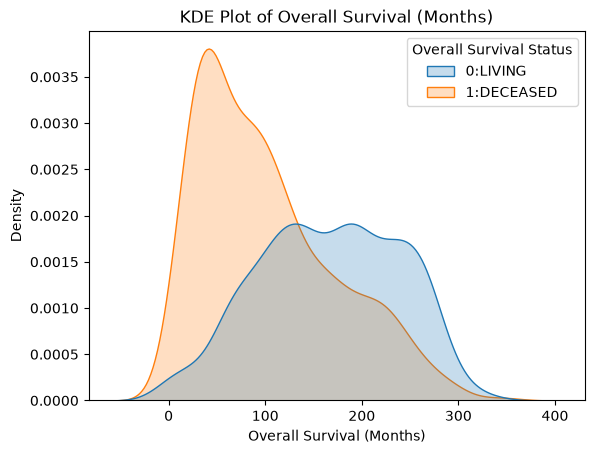

In [12]:
# Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`
# Code recycled from Lab 5 (KDEs)
kde_plot = sns.kdeplot(data=metabric, x='Overall Survival (Months)', fill=True, hue="Overall Survival Status").set(
    title='KDE Plot of Overall Survival (Months)')
print(kde_plot)

In [13]:
# Drop the observations for which tumor stage is 0

metabric = metabric[metabric["Tumor Size"] != 0]
metabric

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1338,70.65,BREAST CONSERVING,Breast Cancer,NO,NO,0.0,9.0,2.040,201.166667,0:LIVING,YES,11.767659,20.0,1.0
1339,75.62,MASTECTOMY,Breast Cancer,NO,NO,0.0,4.0,4.040,105.200000,1:DECEASED,NO,5.230071,20.0,1.0
1340,52.84,BREAST CONSERVING,Breast Cancer,YES,NO,6.0,5.0,5.040,200.333333,0:LIVING,YES,6.537589,20.0,2.0
1341,48.59,MASTECTOMY,Breast Cancer,YES,NO,1.0,6.0,5.060,14.700000,1:DECEASED,YES,7.845106,30.0,2.0


In [15]:
# 2. Use Scikit's `train_test_split` with a `test_size` of .2
#    There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:

# Note of AI Usage: Needed help from Claude OPus 5.5 to write some of this code

# Method 1: Use the Overall Survival (Months) as the target variable
target = "Overall Survival (Months)"
features = ["Age at Diagnosis", "Tumor Size"]

metabric = metabric.dropna(subset=features + [target, "Overall Survival Status"])
X, y = metabric[features], metabric[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Option 1
m1 = LinearRegression().fit(X_train, y_train)
coef1 = pd.Series(m1.coef_, index=features)
pred1 = pd.Series(m1.predict(X_test), index=X_test.index)

# Option 2
dead = metabric["Overall Survival Status"].str.contains("DECEASED")
train_mask = dead.loc[X_train.index]
m2 = LinearRegression().fit(X_train[train_mask], y_train[train_mask])
coef2 = pd.Series(m2.coef_, index=features)
pred2 = pd.Series(m2.predict(X_test), index=X_test.index)

# Print the results...
pd.DataFrame({"option1_impute": coef1, "option2_drop": coef2}).to_csv("flawed_coefs.csv")
pd.DataFrame({"actual": y_test, "option1": pred1, "option2": pred2}).to_csv("flawed_preds.csv")
print(coef1, coef2, sep="\n\n")

Age at Diagnosis   -0.899194
Tumor Size         -1.196030
dtype: float64

Age at Diagnosis    0.300802
Tumor Size         -0.908242
dtype: float64


1. For option 1, a patient who is still alive the recorded months is only how long they have been followed after the study ended.Since there survival time is unknown, we use this to fill in the lower bound of their survival, which is precisiely data imputation, or filling in missing/unknwon values. It is important to note that this is not accurate however, as we do not know the true value, as they have not yet died and will no longer be tracked, which will skew the results.

2. In option 2, survival is treated as missing data as those who are living at the end of the study are dropped. This is not random, as the goal of this procedure is to have the model learn strictly from those who died. As a result, survival is underestmated and so are the corresponding coefficients.

In [27]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                          CensoredNormalMLE Results                           
Dep. Variable:             log_months   Log-Likelihood:                -1227.8
Model:              CensoredNormalMLE   AIC:                             2464.
Method:            Maximum Likelihood   BIC:                             2484.
Date:                Wed, 18 Nov 2026                                         
Time:                        15:28:37                                         
No. Observations:                1074                                         
Df Residuals:                    1070                                         
Df Model:                           2                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                6.7201      0.196     34.247      0.000       6.335       7.105
Age at Diagnosis  

In [22]:
# 3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject 
#    died during the study (and log-months is observed, as in linear-normal regression), and the survival probability 
#    based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, 
#    as in a binary probit).

# Steps...

features = ["Age at Diagnosis", "Tumor Size"]
data = metabric.dropna(subset=features + ["Overall Survival (Months)", "Overall Survival Status"])
data = data[data["Overall Survival (Months)"] > 0]

# Compute dead contribution
dead = metabric[metabric["Overall Survival Status"].astype(str).str.contains("DECEASED", case=False)]
y_dead = np.log(dead["Overall Survival (Months)"])
regression = LinearRegression().fit(dead[features], y_dead)
predictions = regression.predict(dead[features])
residuals = y_dead - predictions
sd = residuals.std()
dead_contribution = norm.logpdf(y_dead, loc=predictions, scale=sd)

# Compute the alive contribution
alive = data[~data["Overall Survival Status"].astype(str).str.contains("DECEASED", case=False)]
y_alive = np.log(alive["Overall Survival (Months)"])
predictions_alive = regression.predict(alive[features])
alive_contribution = norm.logsf(y_alive, loc=predictions_alive, scale=sd)

# Data already in logs so sum...
LL = dead_contribution.sum() + alive_contribution.sum()
print(f"Log-Likelihood: {LL}")

# Note of AI Usage: Tried my hardest to write this code by myself and got most of it done. Where I did not understand, I used Claude Opus 5.5

Log-Likelihood: -1925.8122900560065


In [26]:
# 4. Use this code below to call upon the function for estimation

data["event"] = data["Overall Survival Status"].astype(str).str.contains("DECEASED", case=False).astype(int)
data["log_months"] = np.log(data["Overall Survival (Months)"])

train, test = train_test_split(data, test_size=0.2, random_state=42)

X_train = sm.add_constant(train[features])
y_train = train["log_months"]
ols_all = sm.OLS(y_train, X_train).fit()

**5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches?**

In [32]:
# Note of AI Usage: Used Claude Opus 5.5 to make this table above so I could clearly interpret the results/make the accurate comparisons

results_coef = pd.DataFrame({
    "Option 1 (impute)": pd.Series(np.asarray(coef1), index=features),
    "Option 2 (drop alive)": pd.Series(np.asarray(coef2), index=features),
    "Censored MLE": pd.Series(mle.params[1:-1], index=features),
})

X_test = sm.add_constant(test[features])
results_pred = pd.DataFrame({
    "Option 1 (impute)": np.asarray(pred1),
    "Option 2 (drop alive)": np.asarray(pred2),
    "Censored MLE": np.asarray(X_test @ mle.params[:-1]),
})

results_coef

,Option 1 (impute),Option 2 (drop alive),Censored MLE
Age at Diagnosis,-0.899194,0.300802,-0.019791
Tumor Size,-1.196030,-0.908242,-0.019470


In [ ]:
desc_results = results_pred.describe()
desc_results

,Option 1 (impute),Option 2 (drop alive),Censored MLE
count,269.000000,269.000000,269.000000
mean,126.523597,100.762656,4.994718
std,25.944885,16.475272,0.460855
min,-64.394996,-35.974987,1.843627
25%,116.987659,96.701648,4.792560
50%,130.403631,103.635483,5.052288
75%,141.996070,109.589570,5.308358
max,166.689052,126.591388,5.702772


*Answer*: The first thing to point out is the means for both of the flawed models, and the censored MLE, as there is a steep dropoff that occurs from those two values to the Censored MLE mean. This is because the two flawed models are using raw months, while the censored MLE is using log months. In order to make an accurate comparison, the predictions need to be on the same scale/units.

In [35]:
results_pred = pd.DataFrame({
    "Option 1 (impute)": np.asarray(pred1),
    "Option 2 (drop alive)": np.asarray(pred2),
    "Censored MLE": np.exp(np.asarray(X_test @ mle.params[:-1])),
})

results_pred.describe()

,Option 1 (impute),Option 2 (drop alive),Censored MLE
count,269.000000,269.000000,269.000000
mean,126.523597,100.762656,160.096645
std,25.944885,16.475272,56.368250
min,-64.394996,-35.974987,6.319415
25%,116.987659,96.701648,120.609729
50%,130.403631,103.635483,156.379891
75%,141.996070,109.589570,202.018333
max,166.689052,126.591388,299.696897


As can be seen above in the chart, both of the flawed linear models underpredict survival in months after treatment for the longest surivivng patients. The flawed models largely agree on shorter survival people, but the gap between them grows as the predicted survival time increases. In model 1 the lower bound is taken as the time alive is simple taken as their time of death. THis underestimates the surival times across the data. In the dropping of alive people, there is the most bias as the data becomes completely skewed. It is also important to note that both models yield impossiblek negatuve predictions, which are fixed by the log(prediction)

**Final Note of AI Usage**: All written responses in this lab are my own. AI was used in differnet parts to help me write/understand the code. AI is cited appropriately in such parts.